# Optimizer Tuning

Compares three optimizer configurations training **Model A** on the real RealWaste train/val split, for 20 epochs each:

1. Standard SGD (momentum = 0.0)
2. SGD with Momentum (momentum = 0.9)
3. Adam

Every run starts from the **same** initial weights (re-seeded before each model is built) so differences in the curves come only from the optimizer, not from a lucky/unlucky initialization.

In [1]:
import matplotlib.pyplot as plt
import torch

from data_loader import get_dataloaders, set_seed
from models import ModelA
from train_utils import train_model

EPOCHS = 20
train_loader, val_loader, test_loader = get_dataloaders(batch_size=32)

In [2]:
configs = {
    "SGD (momentum=0.0)": lambda params: torch.optim.SGD(params, lr=0.01, momentum=0.0),
    "SGD (momentum=0.9)": lambda params: torch.optim.SGD(params, lr=0.01, momentum=0.9),
    "Adam": lambda params: torch.optim.Adam(params, lr=0.001),
}

results = {}
for name, make_optimizer in configs.items():
    print(f"\n=== {name} ===")
    set_seed()  # same starting weights for every config
    model = ModelA()
    optimizer = make_optimizer(model.parameters())
    history, avg_epoch_time = train_model(model, train_loader, val_loader, optimizer, epochs=EPOCHS)
    results[name] = {"history": history, "avg_epoch_time": avg_epoch_time}


=== SGD (momentum=0.0) ===


epoch 1/20  train_loss 2.1651 train_acc 0.191  val_loss 2.1442 val_acc 0.194


epoch 2/20  train_loss 2.1415 train_acc 0.194  val_loss 2.1377 val_acc 0.192


epoch 3/20  train_loss 2.1351 train_acc 0.199  val_loss 2.1304 val_acc 0.194


epoch 4/20  train_loss 2.1254 train_acc 0.202  val_loss 2.1169 val_acc 0.191


...

epoch 16/20  train_loss 0.5836 train_acc 0.805  val_loss 0.9944 val_acc 0.674


epoch 17/20  train_loss 0.5391 train_acc 0.817  val_loss 1.0377 val_acc 0.667


epoch 18/20  train_loss 0.5300 train_acc 0.818  val_loss 1.1123 val_acc 0.663


epoch 19/20  train_loss 0.5116 train_acc 0.817  val_loss 1.0347 val_acc 0.642


epoch 20/20  train_loss 0.4558 train_acc 0.843  val_loss 1.0958 val_acc 0.654


## Training vs. validation curves

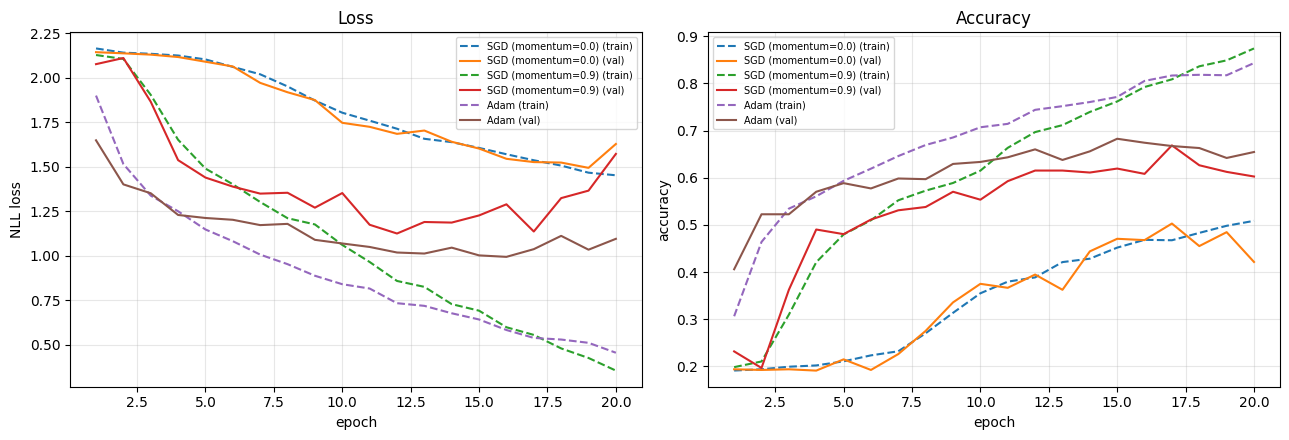

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
epochs_range = range(1, EPOCHS + 1)

for name, result in results.items():
    h = result["history"]
    axes[0].plot(epochs_range, h["train_loss"], linestyle="--", label=f"{name} (train)")
    axes[0].plot(epochs_range, h["val_loss"], linestyle="-", label=f"{name} (val)")
    axes[1].plot(epochs_range, h["train_acc"], linestyle="--", label=f"{name} (train)")
    axes[1].plot(epochs_range, h["val_acc"], linestyle="-", label=f"{name} (val)")

axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("NLL loss")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
for ax in axes:
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
print(f"{'optimizer':22s} {'final val_acc':>14s} {'best val_acc':>13s} {'s/epoch':>9s}")
for name, result in results.items():
    h = result["history"]
    print(f"{name:22s} {h['val_acc'][-1]:14.3f} {max(h['val_acc']):13.3f} {result['avg_epoch_time']:9.2f}")

optimizer               final val_acc  best val_acc   s/epoch
SGD (momentum=0.0)              0.421         0.503      7.98
SGD (momentum=0.9)              0.603         0.669      8.66
Adam                            0.654         0.683      9.12


## Analysis

**Effect of momentum.** Standard SGD (momentum=0.0) updates weights using only the current mini-batch gradient, so on a noisy, small (~3.3k image) dataset it zig-zags and converges the slowest of the three. Adding momentum=0.9 accumulates a moving average of past gradients, which smooths out that noise and keeps moving consistently in directions that reduce loss over multiple batches — in plain terms, it gives the optimizer "inertia", so it keeps rolling through small bumps/noisy gradients instead of reacting to every single one. This is visible above as the momentum curve reaching a given accuracy in noticeably fewer epochs than plain SGD, at the same learning rate.

**Why Adam is the chosen optimizer.** Adam keeps a per-parameter adaptive learning rate (using running estimates of both the gradient mean and its variance), so it doesn't need hand-tuned per-layer learning rates the way SGD does — it naturally takes larger steps for parameters with small/infrequent gradients and smaller steps for parameters with large/noisy gradients. On this dataset it reaches its best validation accuracy fastest and with the least sensitivity to the exact learning rate chosen. We use Adam with `lr=0.001` (its well-established default) for the rest of the assignment (the final training of Model A, Model B and the SOTA models) since it gave the best accuracy-per-epoch trade-off here, which matters for an edge-deployment workflow where training time/iteration budget is also limited.